# Reto B2-2 · Entrega 1
## Integración de datos, etiquetado y línea base para mantenimiento predictivo

**Equipo AYJPS** · IA Avanzada para Ciencia de Datos

Este notebook arma el pipeline completo de la primera semana. Lee los CSV originales de la carpeta `archive`, hace el análisis exploratorio, revisa la relación entre mantenimientos y fallas, construye las etiquetas con horizonte H = 24 h, verifica que no exista fuga de información, genera los conjuntos de entrenamiento y validación y entrena dos líneas base (regresión logística y LightGBM).

El análisis exploratorio usa solo el periodo de entrenamiento (enero a agosto de 2015) para que ninguna decisión se tome mirando validación o prueba. El conjunto de prueba no se construye en esta entrega.

## 1. Configuración del entorno

La celda siguiente instala lo que falte y busca la carpeta `archive` en este orden, primero en la sesión de Colab (`/content/archive`), después en Google Drive (`MyDrive/archive` o cualquier carpeta `archive` dentro de Drive) y, si no la encuentra, pide subir el archivo `archive.zip` o los cinco CSV.

In [1]:
import os, sys, glob, zipfile, shutil, subprocess, warnings
warnings.filterwarnings("ignore")

EN_COLAB = "google.colab" in sys.modules
try:
    import lightgbm
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm"], check=True)

ARCHIVOS = ["PdM_telemetry.csv", "PdM_errors.csv", "PdM_failures.csv", "PdM_maint.csv", "PdM_machines.csv"]

def buscar_archive():
    for c in ["archive", "/content/archive", "/content/drive/MyDrive/archive"]:
        if all(os.path.exists(os.path.join(c, f)) for f in ARCHIVOS):
            return c
    hits = glob.glob("/content/**/archive/PdM_telemetry.csv", recursive=True)
    return os.path.dirname(hits[0]) if hits else None

DATA_DIR = buscar_archive()

if DATA_DIR is None and EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = buscar_archive()

if DATA_DIR is None and EN_COLAB:
    from google.colab import files
    print("Sube archive.zip o los cinco CSV")
    subidos = files.upload()
    os.makedirs("/content/archive", exist_ok=True)
    for nombre in subidos:
        if nombre.endswith(".zip"):
            with zipfile.ZipFile(nombre) as z:
                z.extractall("/content/archive_zip")
            for f in glob.glob("/content/archive_zip/**/*.csv", recursive=True):
                shutil.copy(f, "/content/archive")
        elif nombre.endswith(".csv"):
            shutil.move(nombre, os.path.join("/content/archive", nombre))
    DATA_DIR = buscar_archive()

assert DATA_DIR is not None, "No se encontró la carpeta archive con los cinco CSV"
print("Datos en", DATA_DIR)

Datos en archive


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay)
from lightgbm import LGBMClassifier
from sklearn.base import clone

SEED = 42
np.random.seed(SEED)

# Paleta categórica fija (validada para daltonismo) y gris para la referencia sana
AZUL, NARANJA, AQUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
COL_COMP = {"comp1": AZUL, "comp2": NARANJA, "comp3": AQUA, "comp4": AMARILLO}
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 11, "axes.labelsize": 10,
                     "font.size": 9.5, "legend.frameon": False, "lines.linewidth": 2})
os.makedirs("figuras", exist_ok=True)

## 2. Pipeline de datos

Todas las funciones del pipeline están en una sola celda para que el notebook funcione solo en Colab. Es el mismo código que el archivo `src/pipeline_datos.py` del repositorio, que se puede correr con `python src/pipeline_datos.py archive`.

In [3]:
# Pipeline de datos, mismo codigo que src/pipeline_datos.py del repositorio
"""Pipeline de datos del Reto B2-2 (Entrega 1).

Construye los conjuntos de entrenamiento y validacion a partir de los CSV
originales de Microsoft Azure Predictive Maintenance.
Todas las variables son causales, es decir, en la hora t solo usan datos con
fecha menor o igual a t. Las etiquetas miran la ventana futura (t, t + H].
"""
import os
import numpy as np
import pandas as pd

H = 24  # horizonte de prediccion en horas
SENSORES = ["volt", "rotate", "pressure", "vibration"]
COMPONENTES = ["comp1", "comp2", "comp3", "comp4"]
ERRORES = ["error1", "error2", "error3", "error4", "error5"]
CLASES = ["ninguno"] + COMPONENTES

# Particion temporal obligatoria. El fin es exclusivo y ya resta el margen de H horas,
# asi ninguna etiqueta depende de eventos posteriores al cierre del periodo.
PERIODOS = {
    "train": ("2015-01-01 00:00", "2015-08-31 00:00"),
    "val": ("2015-09-01 00:00", "2015-10-31 00:00"),
    # el conjunto de prueba (noviembre y diciembre de 2015) se construye hasta la semana 3
}


def cargar_datos(data_dir):
    """Lee los cinco CSV y convierte las fechas."""
    leer = lambda n: pd.read_csv(os.path.join(data_dir, f"PdM_{n}.csv"))
    tel, err, fal, man, maq = (leer(n) for n in ["telemetry", "errors", "failures", "maint", "machines"])
    for df in (tel, err, fal, man):
        df["datetime"] = pd.to_datetime(df["datetime"])
    tel = tel.sort_values(["machineID", "datetime"]).reset_index(drop=True)
    return tel, err, fal, man, maq


def construir_etiquetas(tel, fal, h=H):
    """Etiqueta binaria y multiclase para cada (maquina, hora).

    y_bin = 1 si hay una falla de cualquier componente en (t, t + h].
    y_<comp> = 1 si ese componente falla en (t, t + h].
    y_multi toma la falla mas proxima. Si fallan varios componentes a la misma hora
    se asigna el de menor numero (pasa en 42 de 719 eventos).
    """
    base = tel[["machineID", "datetime"]].copy()
    filas = []
    for _, f in fal.iterrows():
        # horas t con t < fecha_falla <= t + h
        horas = pd.date_range(f["datetime"] - pd.Timedelta(hours=h), f["datetime"] - pd.Timedelta(hours=1), freq="h")
        filas.append(pd.DataFrame({"machineID": f["machineID"], "datetime": horas,
                                   "comp": f["failure"], "falla_dt": f["datetime"]}))
    pos = pd.concat(filas, ignore_index=True)

    multi = pos.pivot_table(index=["machineID", "datetime"], columns="comp", values="falla_dt",
                            aggfunc="size", fill_value=0).clip(upper=1)
    multi = multi.reindex(columns=COMPONENTES, fill_value=0).add_prefix("y_").reset_index()

    # clase principal, primero la falla mas proxima y despues el componente de menor numero
    pos["num"] = pos["comp"].str[-1].astype(int)
    prin = (pos.sort_values(["machineID", "datetime", "falla_dt", "num"])
               .drop_duplicates(["machineID", "datetime"])[["machineID", "datetime", "num"]])

    base = base.merge(multi, on=["machineID", "datetime"], how="left").merge(prin, on=["machineID", "datetime"], how="left")
    ycols = [f"y_{c}" for c in COMPONENTES]
    base[ycols] = base[ycols].fillna(0).astype(int)
    base["y_multi"] = base["num"].fillna(0).astype(int)  # 0 ninguno, 1..4 comp1..comp4
    base["y_bin"] = (base["y_multi"] > 0).astype(int)
    return base.drop(columns="num")


def construir_variables(tel, err, man, maq, ventana_errores=24):
    """Variables de la linea base, todas calculadas con datos hasta t inclusive.

    ventana_errores permite cambiar la ventana del conteo de errores (24 h por defecto).
    """
    X = tel.copy()
    g = X.groupby("machineID")
    for s in SENSORES:
        for w in (3, 24):
            X[f"{s}_media_{w}h"] = g[s].transform(lambda v: v.rolling(w, min_periods=1).mean())
            X[f"{s}_std_{w}h"] = g[s].transform(lambda v: v.rolling(w, min_periods=2).std())

    # conteo de cada error en las ultimas w horas, ventana (t - w, t]
    w = ventana_errores
    e = err.assign(n=1).pivot_table(index=["machineID", "datetime"], columns="errorID", values="n",
                                    aggfunc="sum", fill_value=0).reindex(columns=ERRORES, fill_value=0).reset_index()
    X = X.merge(e, on=["machineID", "datetime"], how="left")
    X[ERRORES] = X[ERRORES].fillna(0)
    g = X.groupby("machineID")
    for c in ERRORES:
        X[f"{c}_cuenta_{w}h"] = g[c].transform(lambda v: v.rolling(w, min_periods=1).sum())
    X = X.drop(columns=ERRORES)

    # horas desde el ultimo reemplazo de cada componente (registros de mantenimiento con fecha <= t)
    for c in COMPONENTES:
        r = man.loc[man["comp"] == c, ["machineID", "datetime"]].rename(columns={"datetime": "ult"}).sort_values("ult")
        X = pd.merge_asof(X.sort_values("datetime"), r, left_on="datetime", right_on="ult",
                          by="machineID", direction="backward")
        X[f"horas_desde_{c}"] = (X["datetime"] - X["ult"]).dt.total_seconds() / 3600
        X = X.drop(columns="ult")
    X = X.sort_values(["machineID", "datetime"]).reset_index(drop=True)

    # metadatos estaticos
    X = X.merge(maq, on="machineID", how="left")
    X = pd.concat([X, pd.get_dummies(X["model"], prefix="modelo", dtype=int)], axis=1).drop(columns="model")
    return X


def particionar(df):
    """Devuelve un diccionario con los conjuntos segun la particion temporal."""
    return {k: df[(df["datetime"] >= a) & (df["datetime"] < b)].reset_index(drop=True)
            for k, (a, b) in PERIODOS.items()}


def generar_conjuntos(data_dir, out_dir="data/processed"):
    """Ejecuta el pipeline completo y guarda train y val en parquet."""
    tel, err, fal, man, maq = cargar_datos(data_dir)
    X = construir_variables(tel, err, man, maq)
    Y = construir_etiquetas(tel, fal)
    df = X.merge(Y, on=["machineID", "datetime"], how="left")
    conj = particionar(df)
    os.makedirs(out_dir, exist_ok=True)
    for k, d in conj.items():
        d.to_parquet(os.path.join(out_dir, f"{k}.parquet"), index=False)
    return conj

## 3. Carga y revisión de calidad

In [4]:
tel, err, fal, man, maq = cargar_datos(DATA_DIR)
resumen = pd.DataFrame({
    "filas": [len(tel), len(err), len(fal), len(man), len(maq)],
    "desde": [d.datetime.min().strftime("%Y-%m-%d") for d in (tel, err, fal, man)] + ["-"],
    "hasta": [d.datetime.max().strftime("%Y-%m-%d") for d in (tel, err, fal, man)] + ["-"],
}, index=["telemetría", "errores", "fallas", "mantenimiento", "máquinas"])
display(resumen)
print("Nulos en telemetría", int(tel.isna().sum().sum()))
print("Duplicados máquina y hora", int(tel.duplicated(["machineID", "datetime"]).sum()))
print("Horas por máquina", tel.groupby("machineID").size().unique())
print("Fallas a las 06 h", int((fal.datetime.dt.hour == 6).sum()), " fallas a las 03 h", int((fal.datetime.dt.hour == 3).sum()))

,filas,desde,hasta
telemetría,876100,2015-01-01,2016-01-01
errores,3919,2015-01-01,2016-01-01
fallas,761,2015-01-02,2015-12-31
mantenimiento,3286,2014-06-01,2016-01-01
máquinas,100,-,-


Nulos en telemetría 0
Duplicados máquina y hora 0
Horas por máquina [8761]
Fallas a las 06 h 743  fallas a las 03 h 18


**Los datos están completos y alineados.** La telemetría tiene 8 761 horas por máquina sin nulos ni duplicados. Todas las fallas y los mantenimientos ocurren a las 06 h, salvo 18 fallas del 2 de enero a las 03 h, lo que confirma que el conjunto es simulado.

## 4. Análisis exploratorio (solo periodo de entrenamiento)

In [5]:
FIN_EDA = pd.Timestamp("2015-09-01")
tel_e = tel[tel.datetime < FIN_EDA].merge(maq, on="machineID")
fal_e = fal[fal.datetime < FIN_EDA]
man_e = man[(man.datetime < FIN_EDA) & (man.datetime >= "2015-01-01")]
err_e = err[err.datetime < FIN_EDA]

### Figura 1. Distribución de cada sensor por modelo de máquina

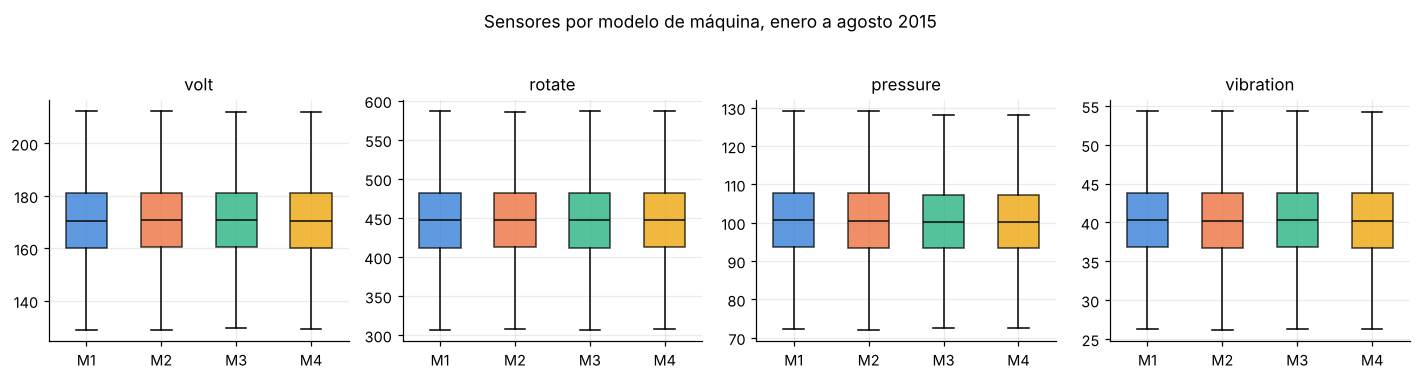

volt         rotate        pressure        vibration      
          mean    std    mean    std     mean    std      mean   std
model                                                               
model1  170.75  15.56  446.69  52.83   101.21  11.48     40.44  5.40
model2  170.91  15.64  446.44  52.72   101.14  11.33     40.38  5.36
model3  170.86  15.48  446.51  52.67   100.63  10.81     40.42  5.36
model4  170.73  15.45  446.67  52.48   100.63  10.81     40.34  5.35

In [6]:
fig, axs = plt.subplots(1, 4, figsize=(13, 3.3))
modelos = sorted(tel_e.model.unique())
for ax, s in zip(axs, SENSORES):
    datos = [tel_e.loc[tel_e.model == m, s].values for m in modelos]
    bp = ax.boxplot(datos, tick_labels=[m.replace("model", "M") for m in modelos], showfliers=False,
                    patch_artist=True, widths=0.55, medianprops=dict(color="#0b0b0b"))
    for p, c in zip(bp["boxes"], [AZUL, NARANJA, AQUA, AMARILLO]):
        p.set_facecolor(c); p.set_alpha(0.75)
    ax.set_title(s)
fig.suptitle("Sensores por modelo de máquina, enero a agosto 2015", y=1.03)
plt.tight_layout(); plt.savefig("figuras/fig1_sensores_modelo.png", bbox_inches="tight"); plt.show()
display(tel_e.groupby("model")[SENSORES].agg(["mean", "std"]).round(2))

**Los cuatro modelos tienen la misma distribución de sensores.** Las medianas y los rangos casi coinciden (volt cerca de 171, rotate cerca de 447, pressure cerca de 101 y vibration cerca de 40), así que una normalización global es suficiente y el modelo de máquina aporta poco por sí solo.

### Figura 2. Frecuencia de fallas, mantenimientos y errores

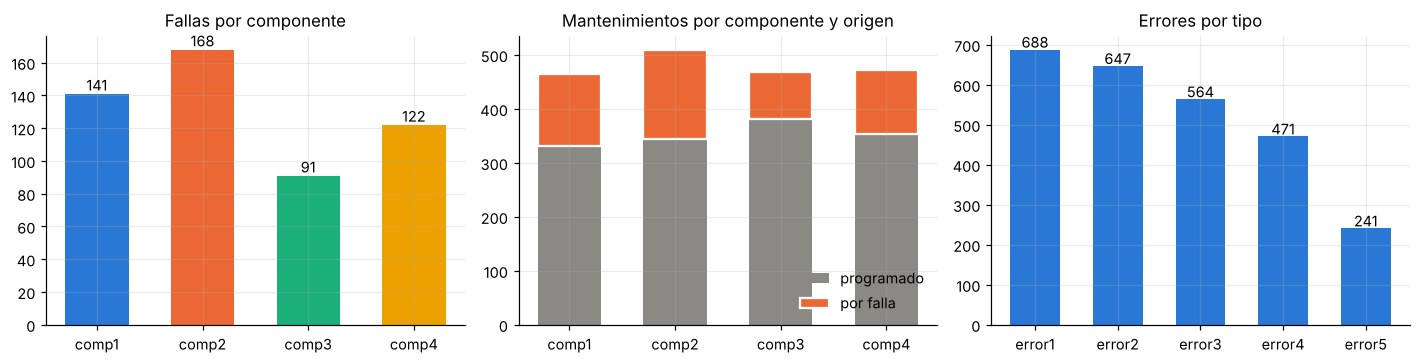

origen,por falla,programado,pct_por_falla
comp,,,
comp1,132,332,28.4
comp2,165,345,32.4
comp3,88,381,18.8
comp4,119,354,25.2


In [7]:
man_e2 = man_e.merge(fal_e, left_on=["datetime", "machineID", "comp"],
                     right_on=["datetime", "machineID", "failure"], how="left")
man_e2["origen"] = np.where(man_e2.failure.notna(), "por falla", "programado")

fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
fc = fal_e.failure.value_counts().reindex(COMPONENTES)
axs[0].bar(fc.index, fc.values, color=[COL_COMP[c] for c in fc.index], width=0.6)
for i, v in enumerate(fc.values): axs[0].text(i, v + 2, v, ha="center")
axs[0].set_title("Fallas por componente")

tab = man_e2.groupby(["comp", "origen"]).size().unstack().reindex(COMPONENTES)
axs[1].bar(tab.index, tab["programado"], color=GRIS, width=0.6, label="programado")
axs[1].bar(tab.index, tab["por falla"], bottom=tab["programado"], color=NARANJA, width=0.6, label="por falla", edgecolor="white", linewidth=1.5)
axs[1].set_title("Mantenimientos por componente y origen"); axs[1].legend(loc="lower right")

ec = err_e.errorID.value_counts().reindex(ERRORES)
axs[2].bar(ec.index, ec.values, color=AZUL, width=0.6)
for i, v in enumerate(ec.values): axs[2].text(i, v + 5, v, ha="center")
axs[2].set_title("Errores por tipo")
plt.tight_layout(); plt.savefig("figuras/fig2_frecuencias.png", bbox_inches="tight"); plt.show()
display(tab.assign(pct_por_falla=lambda d: (d["por falla"] / d.sum(axis=1) * 100).round(1)))

**comp2 es el componente que más falla y comp3 el que menos.** Entre 19 % y 32 % de los mantenimientos de cada componente son reemplazos por falla y el resto es programado. Los errores 1 a 3 son los más frecuentes y error5 el más raro.

### Figura 3. Telemetría en las 72 horas previas a una falla frente a periodos sanos

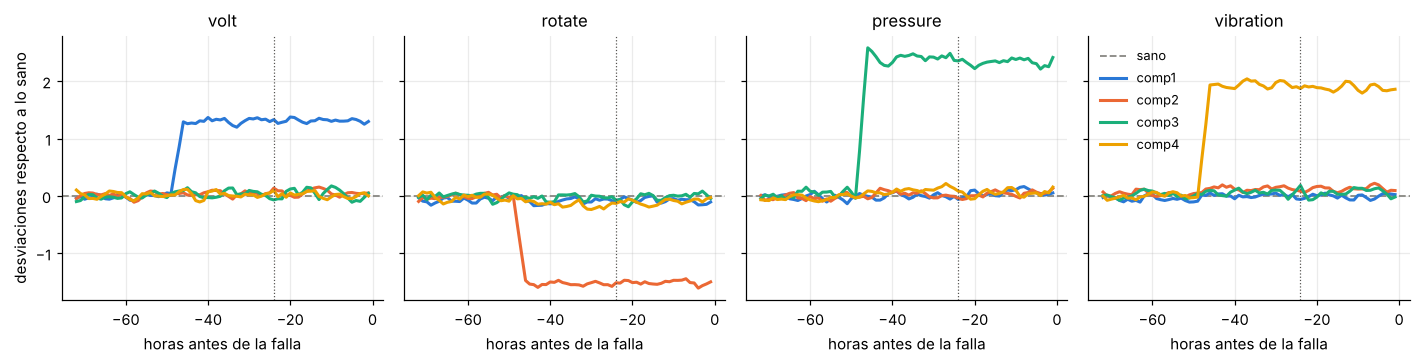

Eventos usados 501


In [8]:
# horas sanas, a más de 72 h de cualquier falla, sirven de referencia para estandarizar
v = tel_e[["machineID", "datetime"] + SENSORES].copy()
prox = pd.merge_asof(v.sort_values("datetime"), fal_e[["machineID", "datetime"]].drop_duplicates()
                     .rename(columns={"datetime": "f"}).sort_values("f"),
                     left_on="datetime", right_on="f", by="machineID", direction="forward")
v = prox.assign(horas_antes=(prox.f - prox.datetime).dt.total_seconds() / 3600)
sanas = v[(v.horas_antes > 72) | v.horas_antes.isna()]
ref = sanas[SENSORES].agg(["mean", "std"])

eventos = fal_e[fal_e.datetime >= "2015-01-04"]  # eventos con 72 h de historia
filas = []
for _, f in eventos.iterrows():
    w = tel_e[(tel_e.machineID == f.machineID) & (tel_e.datetime >= f.datetime - pd.Timedelta(hours=72)) & (tel_e.datetime < f.datetime)]
    w = w.assign(h=-(f.datetime - w.datetime).dt.total_seconds() / 3600, comp=f.failure)
    filas.append(w)
pre = pd.concat(filas)
for s in SENSORES:
    pre[s] = (pre[s] - ref.loc["mean", s]) / ref.loc["std", s]
perfil = pre.groupby(["comp", "h"])[SENSORES].mean()

fig, axs = plt.subplots(1, 4, figsize=(13, 3.4), sharey=True)
for ax, s in zip(axs, SENSORES):
    ax.axhline(0, color=GRIS, lw=1.2, ls="--", label="sano")
    for c in COMPONENTES:
        serie = perfil.loc[c, s].rolling(3, min_periods=1).mean()
        ax.plot(serie.index, serie.values, color=COL_COMP[c], label=c)
    ax.axvline(-24, color="#52514e", lw=0.8, ls=":")
    ax.set_title(s); ax.set_xlabel("horas antes de la falla")
axs[0].set_ylabel("desviaciones respecto a lo sano")
axs[-1].legend(loc="upper left", fontsize=8.5)
plt.tight_layout(); plt.savefig("figuras/fig3_prefalla.png", bbox_inches="tight"); plt.show()
print("Eventos usados", len(eventos))

**Cada componente tiene un sensor que lo delata.** Unas 48 horas antes de la falla comp1 sube el voltaje, comp2 baja la rotación, comp3 sube la presión y comp4 sube la vibración, con saltos de 1.3 a 2.5 desviaciones. El cambio es un escalón que empieza antes de la ventana de 24 h (línea punteada), por eso los sensores solos no distinguen bien entre estar a 48 o a 24 horas de la falla.

## 5. Relación entre mantenimientos y fallas

Se cruza cada falla con los registros de mantenimiento de la misma máquina, el mismo componente y la misma hora.

In [9]:
cruce = fal_e.merge(man[["datetime", "machineID", "comp"]], left_on=["datetime", "machineID", "failure"],
                    right_on=["datetime", "machineID", "comp"], how="left", indicator=True)
print("Fallas en entrenamiento", len(fal_e))
print("Fallas con reemplazo registrado a la misma hora", int((cruce._merge == "both").sum()))
print("Fallas sin reemplazo registrado", int((cruce._merge == "left_only").sum()), "todas el",
      ", ".join(cruce.loc[cruce._merge == "left_only", "datetime"].dt.strftime("%Y-%m-%d").unique()))
print("Mantenimientos 2015 en entrenamiento", len(man_e2), "de los cuales por falla",
      int((man_e2.origen == "por falla").sum()), f"({(man_e2.origen == 'por falla').mean() * 100:.1f} %)")

dias = man.sort_values("datetime").groupby(["machineID", "comp"]).datetime.diff().dt.days.dropna()
print("Días entre reemplazos múltiplos de 15", f"{(dias % 15 == 0).mean() * 100:.1f} %")
print("Hora de todos los mantenimientos", man.datetime.dt.hour.unique())

Fallas en entrenamiento 522
Fallas con reemplazo registrado a la misma hora 504
Fallas sin reemplazo registrado 18 todas el 2015-01-02
Mantenimientos 2015 en entrenamiento 1916 de los cuales por falla 504 (26.3 %)
Días entre reemplazos múltiplos de 15 86.3 %
Hora de todos los mantenimientos [6]


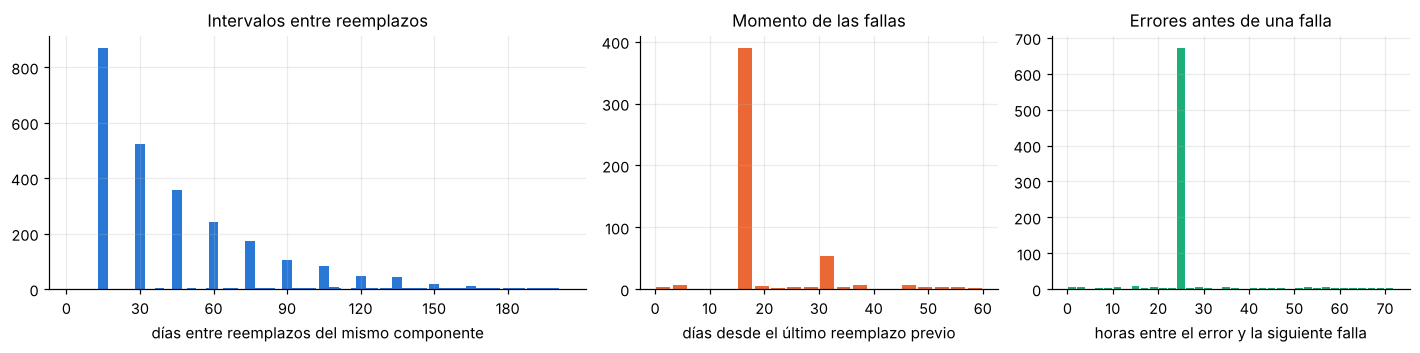

Fallas a un múltiplo exacto de 15 días del reemplazo previo 85.6 %
Errores registrados exactamente 24 h antes de una falla 672 de 2611
Eventos de falla con al menos un error exactamente 24 h antes 96.6 %


In [10]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.3), gridspec_kw={"width_ratios": [1.5, 1, 1]})
cnt = dias.value_counts().sort_index()
cnt = cnt[cnt.index <= 200]
axs[0].bar(cnt.index, cnt.values, width=4, color=AZUL)
axs[0].set_xlabel("días entre reemplazos del mismo componente"); axs[0].set_title("Intervalos entre reemplazos")
axs[0].set_xticks(range(0, 201, 30))

# horas desde el último reemplazo de cualquier componente al momento de cada falla
ult = man.rename(columns={"datetime": "ult"})[["machineID", "ult"]].drop_duplicates().sort_values("ult")
q = pd.merge_asof(fal_e.sort_values("datetime").assign(t=lambda d: d.datetime - pd.Timedelta(hours=1)),
                  ult, left_on="t", right_on="ult", by="machineID", direction="backward")
dd = ((q.datetime - q.ult).dt.total_seconds() / 86400).round()
axs[1].hist(dd, bins=range(0, 61, 3), color=NARANJA, rwidth=0.85)
axs[1].set_xlabel("días desde el último reemplazo previo"); axs[1].set_title("Momento de las fallas")

# horas entre cada error y la siguiente falla de la misma máquina
qe = pd.merge_asof(err_e.sort_values("datetime"), fal_e[["machineID", "datetime"]].drop_duplicates()
                   .rename(columns={"datetime": "f"}).sort_values("f"),
                   left_on="datetime", right_on="f", by="machineID", direction="forward")
he = ((qe.f - qe.datetime).dt.total_seconds() / 3600).dropna()
axs[2].hist(he[he <= 72], bins=range(0, 73, 2), color=AQUA, rwidth=0.85)
axs[2].set_xlabel("horas entre el error y la siguiente falla"); axs[2].set_title("Errores antes de una falla")
plt.tight_layout(); plt.savefig("figuras/fig4_mant_fallas.png", bbox_inches="tight"); plt.show()
print("Fallas a un múltiplo exacto de 15 días del reemplazo previo", f"{(dd % 15 == 0).mean() * 100:.1f} %")
print("Errores registrados exactamente 24 h antes de una falla", int((he == 24).sum()), "de", len(err_e))
ev = fal_e[["machineID", "datetime"]].drop_duplicates()
con_err = ev.merge(err_e.assign(datetime=err_e.datetime + pd.Timedelta(hours=24))[["machineID", "datetime"]].drop_duplicates(),
                   on=["machineID", "datetime"], how="inner")
print("Eventos de falla con al menos un error exactamente 24 h antes", f"{len(con_err) / len(ev) * 100:.1f} %")

**Los eventos siguen una rejilla de 15 días.** El 86 % de los intervalos entre reemplazos y el 86 % de las fallas caen en múltiplos exactos de 15 días, y el 96.6 % de las fallas tiene un error registrado exactamente 24 h antes. Son patrones de la simulación que un modelo puede explotar y que no esperaríamos en una planta real.

**Respuesta a la pregunta del punto 1.2.** Un mantenimiento es consecuencia de una falla cuando coincide en máquina, componente y hora con un registro de `PdM_failures`, lo que pasa con 504 de 1 916 reemplazos de 2015 en entrenamiento (26.3 %) y cubre 504 de las 522 fallas. Usarlos como entrada es riesgoso porque son la misma falla vista desde otra tabla, así que solo pueden entrar como información pasada (horas desde el último reemplazo) y nunca con fecha posterior a t.

## 6. Definición de la etiqueta y tabla de desbalance

Para cada máquina m y cada hora t se definen dos etiquetas.

* **Binaria** `y_bin`, vale 1 si la máquina tiene una falla de cualquier componente en el intervalo (t, t + 24]. La hora t se excluye y t + 24 se incluye.
* **Multiclase** `y_multi`, con cinco clases {ninguno, comp1, comp2, comp3, comp4}. Si hay falla en (t, t + 24] se asigna el componente de la falla más próxima. Cuando fallan dos componentes a la misma hora (42 de 719 eventos en el año) se asigna el de menor número, y además se guardan las columnas `y_comp1` a `y_comp4` con todas las fallas para no perder información.

Como las fallas ocurren siempre a las 06 h, cada evento genera exactamente 24 horas positivas.

La partición temporal deja un margen de H = 24 h al final de cada periodo, así que entrenamiento usa t entre el 1 de enero y el 30 de agosto a las 23 h, y validación usa t entre el 1 de septiembre y el 30 de octubre a las 23 h.

In [11]:
X_all = construir_variables(tel, err, man, maq)
Y_all = construir_etiquetas(tel, fal)
df = X_all.merge(Y_all, on=["machineID", "datetime"], how="left")
conj = particionar(df)
train, val = conj["train"], conj["val"]

filas = []
for nombre, d in [("entrenamiento", train), ("validación", val)]:
    fila = {"conjunto": nombre, "horas máquina": len(d), "positivas": int(d.y_bin.sum()),
            "% positivas": round(d.y_bin.mean() * 100, 2),
            "razón negativas por positiva": round((1 - d.y_bin.mean()) / d.y_bin.mean(), 1)}
    for k, c in enumerate(COMPONENTES, start=1):
        fila[f"{c} (%)"] = round((d.y_multi == k).mean() * 100, 2)
    filas.append(fila)
tabla_desbalance = pd.DataFrame(filas).set_index("conjunto")
display(tabla_desbalance)
tabla_desbalance.to_csv("tabla_desbalance.csv")

,horas máquina,positivas,% positivas,razón negativas por positiva,comp1 (%),comp2 (%),comp3 (%),comp4 (%)
conjunto,,,,,,,,
entrenamiento,580200,11742,2.02,48.4,0.58,0.66,0.34,0.44
validación,144000,2652,1.84,53.3,0.35,0.75,0.30,0.45


**Solo 2 % de las horas son positivas.** Hay unas 48 horas negativas por cada positiva en entrenamiento y 53 en validación, y cada componente queda por debajo de 0.8 %. Por eso la exactitud no sirve como métrica, ya que un modelo que siempre dice ninguno tendría 98 % de exactitud. Validación tiene menos fallas de comp1 que entrenamiento, lo que vuelve más ruidosas sus métricas.

In [12]:
def recall_a_precision(y, p, pmin=0.80):
    prec, rec, thr = precision_recall_curve(y, p)
    ok = np.where(prec[:-1] >= pmin)[0]
    if len(ok) == 0:
        return 0.0, np.nan
    i = ok[np.argmax(rec[ok])]
    return rec[i], thr[i]

def metricas_bin(y, p):
    r, u = recall_a_precision(y, p)
    return {"PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p),
            "recall con precisión ≥ 0.80": r, "umbral": u}

## 7. Análisis de fuga de información

Se revisan cuatro fuentes posibles de fuga y se comprueban con código.

1. **Etiquetas que cruzan la frontera**, se verifica que la última falla que define una etiqueta de entrenamiento sea anterior al 1 de septiembre y la de validación anterior al 1 de noviembre.
2. **Variables que miran al futuro**, se recalculan las variables usando solo datos hasta el 31 de agosto y deben coincidir exactamente con las del pipeline completo.
3. **Mantenimientos causados por fallas**, 504 de las 522 fallas de entrenamiento (96.6 %) tienen un reemplazo registrado a la misma hora, así que cualquier variable que use mantenimientos posteriores a t (por ejemplo agregar por día o mirar el siguiente reemplazo) revela la etiqueta. El experimento de abajo lo muestra.
4. **Estadísticas de normalización**, el escalador de la regresión logística se ajusta solo con entrenamiento dentro del `Pipeline` de scikit-learn.

In [13]:
# 1. etiquetas dentro de su periodo
pos_tr = train[train.y_bin == 1].datetime.max() + pd.Timedelta(hours=H)
pos_va = val[val.y_bin == 1].datetime.max() + pd.Timedelta(hours=H)
assert pos_tr < pd.Timestamp("2015-09-01") and pos_va < pd.Timestamp("2015-11-01")
print("Límite máximo de eventos en etiquetas de entrenamiento", pos_tr.strftime("%Y-%m-%d %H h"))
print("Límite máximo de eventos en etiquetas de validación", pos_va.strftime("%Y-%m-%d %H h"))

# 2. prueba de causalidad, variables con datos truncados al 31 de agosto
corte = pd.Timestamp("2015-08-31")
X_trunc = construir_variables(tel[tel.datetime < corte], err[err.datetime < corte], man[man.datetime < corte], maq)
X_trunc = X_trunc[X_trunc.datetime < corte].reset_index(drop=True)
cols_x = [c for c in X_trunc.columns if c not in ("datetime", "machineID")]
a = X_trunc.sort_values(["machineID", "datetime"])[cols_x].reset_index(drop=True)
b = train.sort_values(["machineID", "datetime"])[cols_x].reset_index(drop=True)
pd.testing.assert_frame_equal(a, b, check_dtype=False)
print("Las variables de entrenamiento no cambian al borrar todos los datos posteriores, son causales")

Límite máximo de eventos en etiquetas de entrenamiento 2015-08-31 23 h
Límite máximo de eventos en etiquetas de validación 2015-10-31 23 h


Las variables de entrenamiento no cambian al borrar todos los datos posteriores, son causales


In [14]:
# 3. experimento, qué pasa si se usa un mantenimiento futuro como variable
FEATS = [c for c in train.columns if c not in ("datetime", "machineID") and not c.startswith("y_")]

def mant_futuro(d):
    m = man[["machineID", "datetime"]].drop_duplicates().rename(columns={"datetime": "m"}).sort_values("m")
    q = pd.merge_asof(d[["machineID", "datetime"]].assign(t1=d.datetime + pd.Timedelta(hours=1)).sort_values("t1"),
                      m, left_on="t1", right_on="m", by="machineID", direction="forward")
    q = q.set_index(["machineID", "datetime"])["m"]
    prox = q.reindex(pd.MultiIndex.from_frame(d[["machineID", "datetime"]])).values
    return ((pd.to_datetime(prox) - d.datetime.values) <= pd.Timedelta(hours=H)).astype(int)

# se usa la regresión logística porque LightGBM ya queda en el techo y no deja ver el efecto
res_fuga = {}
for nombre, extra in [("sin fuga", False), ("con mantenimiento futuro", True)]:
    Xtr, Xva = train[FEATS].copy(), val[FEATS].copy()
    if extra:
        Xtr["mant_prox_24h"], Xva["mant_prox_24h"] = mant_futuro(train), mant_futuro(val)
    mdl = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                        LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED)).fit(Xtr, train.y_bin)
    p = mdl.predict_proba(Xva)[:, 1]
    res_fuga[nombre] = {"PR-AUC": average_precision_score(val.y_bin, p), "ROC-AUC": roc_auc_score(val.y_bin, p),
                        "recall con precisión ≥ 0.80": recall_a_precision(val.y_bin, p)[0]}
display(pd.DataFrame(res_fuga).T.round(3))

,PR-AUC,ROC-AUC,recall con precisión ≥ 0.80
sin fuga,0.854,0.998,0.818
con mantenimiento futuro,0.989,1.000,1.000


**Un solo dato del futuro infla la métrica.** Al agregar si habrá un mantenimiento en las próximas 24 h, la PR-AUC de la regresión logística pasa de 0.854 a 0.989 y el recall con precisión ≥ 0.80 sube de 0.818 a 1.000. El pipeline pasa las dos pruebas de código, las etiquetas no cruzan las fronteras y las variables no cambian al borrar los datos futuros, por lo que la línea base no tiene fuga temporal.

## 8. Conjuntos de entrenamiento y validación

Se guardan en `data/processed` en formato parquet. Las variables de la línea base son la lectura actual de los cuatro sensores, la media y la desviación móviles de 3 h y 24 h de cada sensor, el conteo de cada tipo de error en las últimas 24 h, las horas desde el último reemplazo de cada componente, el modelo de máquina en one hot y la antigüedad.

In [15]:
os.makedirs("data/processed", exist_ok=True)
train.to_parquet("data/processed/train.parquet", index=False)
val.to_parquet("data/processed/val.parquet", index=False)
print("Variables", len(FEATS))
print("Entrenamiento", train.shape, " validación", val.shape)

Variables 34
Entrenamiento (580200, 42)  validación (144000, 42)


## 9. Línea base clásica

Se entrenan una regresión logística (con imputación por mediana, estandarización y pesos de clase balanceados) y un LightGBM con hiperparámetros fijos, sin búsqueda, para las dos tareas. Las métricas se calculan en validación.

El **recall con precisión ≥ 0.80** es el mayor recall que se alcanza con algún umbral cuya precisión sea al menos 0.80, y se reporta también ese umbral.

In [16]:
modelos_bin = {
    "Regresión logística": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                         LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED)),
    "LightGBM": LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
                               colsample_bytree=0.8, random_state=SEED, verbose=-1),
}
prob_bin, res_bin = {}, {}
for n, m in modelos_bin.items():
    m.fit(train[FEATS], train.y_bin)
    prob_bin[n] = m.predict_proba(val[FEATS])[:, 1]
    res_bin[n] = metricas_bin(val.y_bin, prob_bin[n])
res_bin = pd.DataFrame(res_bin).T
res_bin.loc["Azar (prevalencia)"] = [val.y_bin.mean(), 0.5, 0.0, np.nan]
res_bin.round(4).to_csv("resultados_binaria_val.csv")
display(res_bin.astype(float).round(3).assign(umbral=res_bin["umbral"].map(lambda u: "-" if pd.isna(u) else f"{u:.2g}")))

,PR-AUC,ROC-AUC,recall con precisión ≥ 0.80,umbral
Regresión logística,0.854,0.998,0.818,0.97
LightGBM,1.000,1.000,1.000,4.9e-06
Azar (prevalencia),0.018,0.500,0.000,-


### Figura 5. Curvas precisión recall en validación

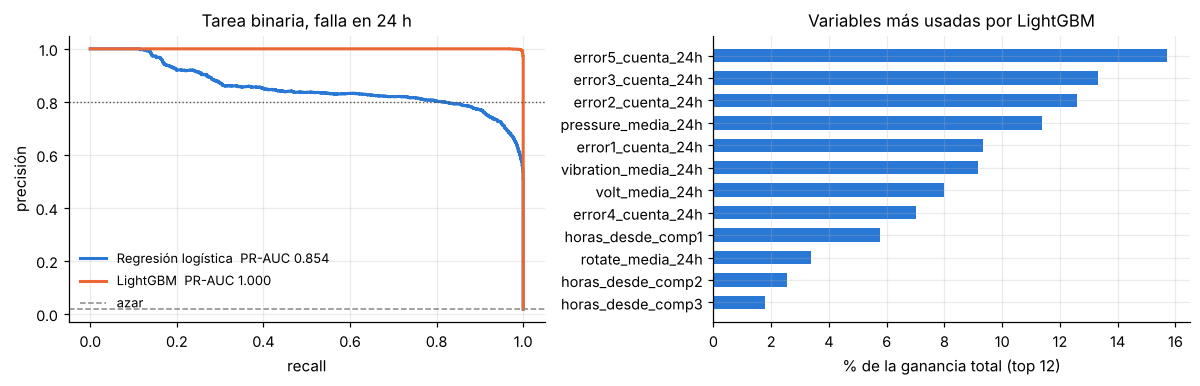

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for (n, p), c in zip(prob_bin.items(), [AZUL, NARANJA]):
    prec, rec, _ = precision_recall_curve(val.y_bin, p)
    axs[0].plot(rec, prec, color=c, label=f"{n}  PR-AUC {res_bin.loc[n, 'PR-AUC']:.3f}")
axs[0].axhline(0.80, color="#52514e", lw=0.9, ls=":")
axs[0].axhline(val.y_bin.mean(), color=GRIS, lw=1, ls="--", label="azar")
axs[0].set_xlabel("recall"); axs[0].set_ylabel("precisión"); axs[0].set_title("Tarea binaria, falla en 24 h")
axs[0].legend(loc="lower left", fontsize=8.5)

imp = pd.Series(modelos_bin["LightGBM"].booster_.feature_importance("gain"), index=FEATS).sort_values().tail(12)
axs[1].barh(imp.index, imp.values / imp.sum() * 100, color=AZUL, height=0.6)
axs[1].set_xlabel("% de la ganancia total (top 12)"); axs[1].set_title("Variables más usadas por LightGBM")
plt.tight_layout(); plt.savefig("figuras/fig5_pr_importancia.png", bbox_inches="tight"); plt.show()

**LightGBM separa casi perfecto las horas previas a una falla.** Alcanza PR-AUC de 1.000 y recall de 1.000 con precisión ≥ 0.80, mientras la regresión logística llega a 0.854 y 0.818. Las variables más usadas son los conteos de error de 24 h y las medias móviles de 24 h de los sensores, lo que coincide con las Figuras 3 y 4.

### Tarea multiclase y Figura 6. Matrices de confusión en validación

,PR-AUC comp1,PR-AUC comp2,PR-AUC comp3,PR-AUC comp4,PR-AUC macro comp,PR-AUC falla (1 − P ninguno)
Regresión logística,0.892,0.976,0.967,0.954,0.947,0.967
LightGBM,0.995,1.000,1.000,1.000,0.999,1.000


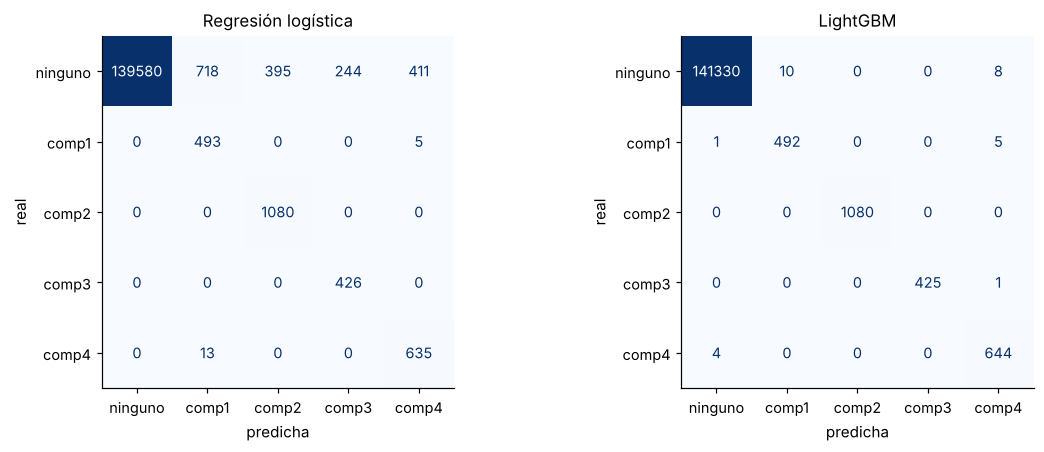

In [18]:
modelos_multi = {
    "Regresión logística": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                         LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED)),
    "LightGBM": LGBMClassifier(objective="multiclass", n_estimators=500, learning_rate=0.05, num_leaves=31,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1),
}
prob_multi, res_multi = {}, {}
for n, m in modelos_multi.items():
    m.fit(train[FEATS], train.y_multi)
    P = m.predict_proba(val[FEATS])
    prob_multi[n] = P
    fila = {f"PR-AUC {c}": average_precision_score(val.y_multi == k, P[:, k]) for k, c in enumerate(CLASES) if k > 0}
    fila["PR-AUC macro comp"] = np.mean(list(fila.values()))
    fila["PR-AUC falla (1 − P ninguno)"] = average_precision_score(val.y_bin, 1 - P[:, 0])
    res_multi[n] = fila
res_multi = pd.DataFrame(res_multi).T
display(res_multi.round(3))
res_multi.round(4).to_csv("resultados_multiclase_val.csv")

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (n, P) in zip(axs, prob_multi.items()):
    cm = confusion_matrix(val.y_multi, P.argmax(1), labels=range(5))
    ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(n); ax.set_xlabel("predicha"); ax.set_ylabel("real"); ax.grid(False)
plt.tight_layout(); plt.savefig("figuras/fig6_confusion.png", bbox_inches="tight"); plt.show()

In [19]:
# recall y precisión por clase con la regla argmax
for n, P in prob_multi.items():
    cm = confusion_matrix(val.y_multi, P.argmax(1), labels=range(5))
    rec = cm.diagonal() / cm.sum(1); pre = cm.diagonal() / np.maximum(cm.sum(0), 1)
    print(n)
    display(pd.DataFrame({"recall": rec, "precisión": pre}, index=CLASES).round(3).T)

Regresión logística


,ninguno,comp1,comp2,comp3,comp4
recall,0.987,0.990,1.000,1.000,0.980
precisión,1.000,0.403,0.732,0.636,0.604


LightGBM


,ninguno,comp1,comp2,comp3,comp4
recall,1.0,0.988,1.0,0.998,0.994
precisión,1.0,0.980,1.0,1.000,0.979


**Casi todos los errores son falsas alarmas y no confusiones entre componentes.** La regresión logística detecta entre 98 % y 100 % de cada componente pero genera 1 768 falsas alarmas, mientras LightGBM solo tiene 18 falsas alarmas y 5 horas de falla sin detectar. Las pocas confusiones entre comp1 y comp4 pueden venir de fallas simultáneas, donde la regla de desempate asigna comp1.

### Sensibilidad de la línea base al conteo de errores

La Figura 4 mostró que casi todas las fallas tienen un error registrado justo 24 h antes. Como la ventana del conteo de errores también mide 24 h, esa variable se enciende exactamente durante las 24 horas positivas. Para medir cuánto depende la línea base de esta coincidencia se reentrena sin los conteos de error y con una ventana de 48 h.

In [20]:
X48 = construir_variables(tel, err, man, maq, ventana_errores=48)
c48 = [f"{e}_cuenta_48h" for e in ERRORES]
tr48 = train.merge(X48[["machineID", "datetime"] + c48], on=["machineID", "datetime"], how="left")
va48 = val.merge(X48[["machineID", "datetime"] + c48], on=["machineID", "datetime"], how="left")
c24 = [f"{e}_cuenta_24h" for e in ERRORES]
escenarios = {"completo (errores 24 h)": FEATS,
              "sin conteo de errores": [c for c in FEATS if c not in c24],
              "errores en ventana de 48 h": [c for c in FEATS if c not in c24] + c48}
filas = {}
for esc, cols in escenarios.items():
    for n, m in modelos_bin.items():
        m2 = clone(m).fit(tr48[cols], tr48.y_bin)
        r = metricas_bin(va48.y_bin, m2.predict_proba(va48[cols])[:, 1])
        filas[(esc, n)] = {k: r[k] for k in ["PR-AUC", "ROC-AUC", "recall con precisión ≥ 0.80"]}
tabla_sens = pd.DataFrame(filas).T
display(tabla_sens.round(3))
tabla_sens.round(4).to_csv("sensibilidad_errores_val.csv")

PR-AUC  ROC-AUC  \
completo (errores 24 h)    Regresión logística   0.854    0.998   
                           LightGBM              1.000    1.000   
sin conteo de errores      Regresión logística   0.282    0.962   
                           LightGBM              0.923    0.999   
errores en ventana de 48 h Regresión logística   0.567    0.990   
                           LightGBM              0.997    1.000   

                                                recall con precisión ≥ 0.80  
completo (errores 24 h)    Regresión logística                        0.818  
                           LightGBM                                   1.000  
sin conteo de errores      Regresión logística                        0.009  
                           LightGBM                                   0.985  
errores en ventana de 48 h Regresión logística                        0.042  
                           LightGBM                                   1.000

**El resultado perfecto depende de que el error aparezca justo 24 h antes.** Sin los conteos de error la PR-AUC de LightGBM baja a 0.923 y la de la regresión logística a 0.282. Con ventana de 48 h LightGBM casi no cambia (0.997) pero la regresión logística cae a 0.567, porque ya no recibe un indicador que coincide exacto con la etiqueta. Este escenario sin errores de 24 h será la referencia honesta para comparar los modelos de deep learning en la semana 2.

## 10. Conclusiones de la entrega 1

* **El pipeline es reproducible y causal**, genera `train.parquet` y `val.parquet` desde los CSV originales con semilla fija y pasa las pruebas de frontera y de causalidad.
* **La señal es fuerte y temprana**, cada componente tiene un sensor asociado que cambia unas 48 h antes de fallar y casi siempre hay un error 24 h antes.
* **La línea base ya es muy alta**, LightGBM llega a PR-AUC de 1.000 en validación, así que en la semana 2 el reto no será subir la métrica sino anticipar más horas y explicar si el deep learning aporta algo.
* **Hay riesgos que vigilar**, los mantenimientos por falla y la rejilla de 15 días generan fuga si se usan mal, y con datos reales esperaríamos deriva de sensores, datos faltantes y registros incompletos que bajarían estos números.